# RQ4 — FLACCS-adapted paired comparison

Compares GPT-OSS 20B and FLACCS on 30 projects (adapted 10-class cohort, 2,573 commits).

Input: `../metrics/evaluation_macro_f1.csv` (also located when run from the repository root).

Outputs (displayed inline; no files are written): descriptive statistics, normality test of the paired differences (GPT-OSS − FLACCS), the paired test with its effect size, and a figure of the per-project differences.

Run: *Run All*.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

try:
    import pingouin as pg
except ImportError as exc:
    raise ImportError(
        "This notebook requires 'pingouin'. Install the "
        "dependencies from requirements.txt before running the analysis."
    ) from exc

DATA_FILENAME = "evaluation_macro_f1.csv"
EXPECTED_PROJECTS = 30
EXPECTED_COLUMNS = ['project', 'gpt-oss', 'flaccs', 'delta_gpt_minus_flaccs']
MODEL_COLUMNS = ["gpt-oss", "flaccs"]
DELTA_COLUMN = "delta_gpt_minus_flaccs"

DISPLAY_LABELS = {
    "gpt-oss": "GPT-OSS 20B",
    "flaccs": "FLACCS",
}


def locate_evaluation_file(filename=DATA_FILENAME):
    """Locate the adapted evaluation table from the notebook folder or repo root."""
    cwd = Path.cwd().resolve()
    candidates = [
        cwd / ".." / "metrics" / filename,
        cwd / "metrics" / filename,
        cwd / "results" / "rq4_2" / "related_work_artifacts" / "flaccs" / "metrics" / filename,
    ]

    for parent in (cwd, *cwd.parents):
        candidates.append(
            parent / "results" / "rq4_2" / "related_work_artifacts" / "flaccs" / "metrics" / filename
        )

    seen = []
    for candidate in candidates:
        candidate = candidate.resolve()
        if candidate in seen:
            continue
        seen.append(candidate)
        if candidate.is_file():
            return candidate

    checked = "\n".join(f"  - {path}" for path in seen)
    raise FileNotFoundError(
        f"Could not locate {filename}. Checked:\n{checked}"
    )


DATA_PATH = locate_evaluation_file()

df_raw = pd.read_csv(DATA_PATH)
df_raw.columns = df_raw.columns.str.strip()

missing_columns = [c for c in EXPECTED_COLUMNS if c not in df_raw.columns]
extra_columns = [c for c in df_raw.columns if c not in EXPECTED_COLUMNS]
if missing_columns or extra_columns:
    raise ValueError(
        "Unexpected evaluation schema. "
        f"Missing={missing_columns}; extra={extra_columns}."
    )

if len(df_raw) != EXPECTED_PROJECTS:
    raise ValueError(
        f"Expected {EXPECTED_PROJECTS} project rows, found {len(df_raw)}."
    )

if df_raw["project"].isna().any() or (df_raw["project"].astype(str).str.strip() == "").any():
    raise ValueError("Project identifiers must be non-empty.")

if df_raw["project"].duplicated().any():
    duplicates = df_raw.loc[df_raw["project"].duplicated(), "project"].astype(str).tolist()
    raise ValueError(f"Duplicate project identifiers were found: {duplicates}")

for column in [*MODEL_COLUMNS, DELTA_COLUMN]:
    df_raw[column] = pd.to_numeric(df_raw[column], errors="raise")

if df_raw[[*MODEL_COLUMNS, DELTA_COLUMN]].isna().any().any():
    raise ValueError(
        "The adapted evaluation must contain complete paired scores for all 30 projects."
    )

invalid_mask = (df_raw[MODEL_COLUMNS] < 0) | (df_raw[MODEL_COLUMNS] > 1)
if invalid_mask.any().any():
    raise ValueError("Macro-F1 values must lie in the [0, 1] interval.")

computed_delta = df_raw["gpt-oss"] - df_raw["flaccs"]
if not np.allclose(
    computed_delta.to_numpy(),
    df_raw[DELTA_COLUMN].to_numpy(),
    rtol=0.0,
    atol=1e-12,
):
    raise ValueError(
        f"{DELTA_COLUMN} is inconsistent with gpt-oss - flaccs."
    )

paired_data = (
    df_raw.set_index("project")[MODEL_COLUMNS]
    .rename(columns=DISPLAY_LABELS)
    .copy()
)
MODEL_A, MODEL_B = paired_data.columns.tolist()

print(f"Evaluation file: {DATA_PATH}")
print(f"Complete paired projects: {len(paired_data)}")
print(f"Comparison: {MODEL_A} − {MODEL_B}")
display(paired_data.head())


def _round_small(frame, decimals):
    """Round for display; nonzero values that round to 0 are shown as <0.001."""
    rounded = frame.round(decimals)
    out = rounded.astype(object)
    for column in frame.select_dtypes("number").columns:
        tiny = (frame[column] != 0) & (rounded[column] == 0)
        out.loc[tiny, column] = "<0.001"
    return out


Evaluation file: results\rq4_2\related_work_artifacts\flaccs\metrics\evaluation_macro_f1.csv
Complete paired projects: 30
Comparison: GPT-OSS 20B − FLACCS


,GPT-OSS 20B,FLACCS
project,,
angular,0.516510,0.548090
ant-design,0.376825,0.320936
biome,0.499919,0.440414
bun,0.575132,0.347788
clap,0.570747,0.743283


## Analysis functions

In [2]:
from scipy.stats import shapiro, t, ttest_rel


def _format_p_plain(p_value, digits=4):
    p_value = float(p_value)
    if p_value < 0.001:
        return "<.001"
    return f"{p_value:.{digits}f}".lstrip("0")


def _pingouin_value(row, *candidates):
    normalized = {
        str(column).lower().replace("-", "_"): column
        for column in row.index
    }
    for candidate in candidates:
        key = candidate.lower().replace("-", "_")
        if key in normalized:
            return row[normalized[key]]
    raise KeyError(
        f"None of these columns were found: {candidates}"
    )


def _effect_magnitude(effect, route):
    value = abs(float(effect))
    if route == "parametric":
        if value < 0.2:
            return "Negligible"
        if value < 0.5:
            return "Small"
        if value < 0.8:
            return "Medium"
        return "Large"

    if value < 0.1:
        return "Negligible"
    if value < 0.3:
        return "Small"
    if value < 0.5:
        return "Medium"
    return "Large"


def run_flaccs_comparison(
    data,
    model_a,
    model_b,
    alpha=0.05,
):
    values_a = data[model_a]
    values_b = data[model_b]
    differences = values_a - values_b
    n = len(differences)

    shapiro_statistic, shapiro_p = shapiro(differences)
    route = (
        "parametric"
        if shapiro_p >= alpha
        else "non-parametric"
    )

    model_summary = pd.DataFrame({
        "N": [n, n],
        "Mean Macro-F1": [values_a.mean(), values_b.mean()],
        "SD": [values_a.std(ddof=1), values_b.std(ddof=1)],
        "Median": [values_a.median(), values_b.median()],
        "Minimum": [values_a.min(), values_b.min()],
        "Maximum": [values_a.max(), values_b.max()],
    }, index=[model_a, model_b])
    model_summary.index.name = "Model"

    mean_difference = differences.mean()
    sd_difference = differences.std(ddof=1)

    if route == "parametric":
        statistic, p_value = ttest_rel(values_a, values_b)
        standard_error = differences.sem()
        critical_t = t.ppf(0.975, df=n - 1)
        ci_lower = mean_difference - critical_t * standard_error
        ci_upper = mean_difference + critical_t * standard_error

        if np.allclose(differences, 0):
            effect = 0.0
        else:
            effect = pg.compute_effsize(
                values_a.to_numpy(),
                values_b.to_numpy(),
                paired=True,
                eftype="hedges",
            )

        statistic_name = "t"
        degrees_freedom = n - 1
        effect_name = "Hedges' g"
    else:
        if np.allclose(differences, 0):
            statistic = 0.0
            p_value = 1.0
            effect = 0.0
        else:
            wilcoxon = pg.wilcoxon(
                values_a.to_numpy(),
                values_b.to_numpy(),
                alternative="two-sided",
            ).iloc[0]
            statistic = _pingouin_value(
                wilcoxon,
                "W_val",
                "W-val",
            )
            p_value = _pingouin_value(
                wilcoxon,
                "p_val",
                "p-val",
            )
            effect = _pingouin_value(wilcoxon, "RBC")

        ci_lower = np.nan
        ci_upper = np.nan
        statistic_name = "W"
        degrees_freedom = np.nan
        effect_name = "Rank-biserial correlation"

    comparison = {
        "Comparison": f"{model_a} − {model_b}",
        "N": n,
        "Mean Difference": mean_difference,
        "SD Difference": sd_difference,
        "CI95 Lower": ci_lower,
        "CI95 Upper": ci_upper,
        "Statistic name": statistic_name,
        "Statistic": float(statistic),
        "df": degrees_freedom,
        "p": float(p_value),
        "Effect name": effect_name,
        "Effect": float(effect),
        "Effect magnitude": _effect_magnitude(effect, route),
        "Significant": bool(p_value < alpha),
    }

    direction = pd.DataFrame([{
        f"{model_a} higher": int((differences > 0).sum()),
        f"{model_b} higher": int((differences < 0).sum()),
        "Ties": int((differences == 0).sum()),
        "Total projects": n,
    }])

    project_results = data[[model_a, model_b]].copy()
    project_results["Difference"] = differences
    project_results["Higher model"] = np.where(
        differences > 0,
        model_a,
        np.where(differences < 0, model_b, "Tie"),
    )
    project_results = project_results.sort_values(
        "Difference",
        ascending=False,
    )

    print("DESCRIPTIVE MODEL TABLE")
    display(_round_small(model_summary, 4))
    print("SHAPIRO-WILK TEST ON PAIRED DIFFERENCES")
    display(pd.DataFrame([{
        "Comparison": f"{model_a} − {model_b}",
        "N": n,
        "W": round(shapiro_statistic, 4),
        "p": _format_p_plain(shapiro_p),
        "Normality not rejected": bool(shapiro_p >= alpha),
    }]))
    print(f"SELECTED ROUTE: {route}")
    print("PAIRED COMPARISON")
    display(_round_small(pd.DataFrame([comparison]), 4))
    print("PROJECT-LEVEL DIRECTION")
    display(direction)

    return {
        "data": data,
        "model_a": model_a,
        "model_b": model_b,
        "differences": differences,
        "model_summary": model_summary,
        "shapiro_W": float(shapiro_statistic),
        "shapiro_p": float(shapiro_p),
        "route": route,
        "comparison": comparison,
        "direction": direction,
        "project_results": project_results,
        "alpha": alpha,
    }


## Run the comparison

In [3]:
flaccs_analysis = run_flaccs_comparison(
    data=paired_data,
    model_a=MODEL_A,
    model_b=MODEL_B,
)


DESCRIPTIVE MODEL TABLE


,N,Mean Macro-F1,SD,Median,Minimum,Maximum
Model,,,,,,
GPT-OSS 20B,30,0.474,0.1135,0.4827,0.1967,0.6841
FLACCS,30,0.4597,0.1061,0.4545,0.2524,0.7433


SHAPIRO-WILK TEST ON PAIRED DIFFERENCES


,Comparison,N,W,p,Normality not rejected
0,GPT-OSS 20B − FLACCS,30,0.9877,.9736,True


SELECTED ROUTE: parametric
PAIRED COMPARISON


,Comparison,N,Mean Difference,SD Difference,CI95 Lower,CI95 Upper,Statistic name,Statistic,df,p,Effect name,Effect,Effect magnitude,Significant
0,GPT-OSS 20B − FLACCS,30,0.0144,0.0985,-0.0224,0.0512,t,0.7981,29,0.4313,Hedges' g,0.129,Negligible,False


PROJECT-LEVEL DIRECTION


,GPT-OSS 20B higher,FLACCS higher,Ties,Total projects
0,16,14,0,30


## Project-level paired differences

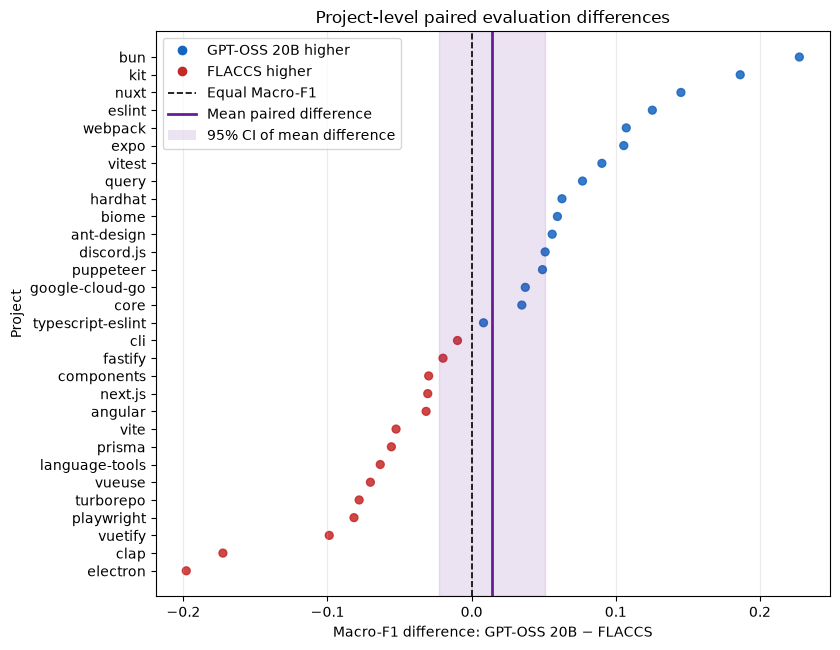

In [4]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

project_results = flaccs_analysis["project_results"].copy()
project_results = project_results.sort_values(
    "Difference",
    ascending=True,
)

figure_height = max(6, 0.22 * len(project_results))
fig, ax = plt.subplots(figsize=(8.5, figure_height))
ax.grid(True, axis="x", alpha=0.25)

colors = np.where(
    project_results["Difference"] >= 0,
    "#1565C0",
    "#C62828",
)
ax.scatter(
    project_results["Difference"],
    project_results.index.astype(str),
    c=colors,
    s=32,
    alpha=0.85,
)
ax.axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label="Equal Macro-F1",
)

comparison = flaccs_analysis["comparison"]
ax.axvline(
    comparison["Mean Difference"],
    color="#6A1B9A",
    linewidth=2,
    label="Mean paired difference",
)

if flaccs_analysis["route"] == "parametric":
    ax.axvspan(
        comparison["CI95 Lower"],
        comparison["CI95 Upper"],
        color="#6A1B9A",
        alpha=0.12,
        label="Unadjusted 95% CI",
    )

ax.set_xlabel(f"Macro-F1 difference: {MODEL_A} − {MODEL_B}")
ax.set_ylabel("Project")
ax.set_title("Project-level paired evaluation differences")
legend_handles = [
    Line2D(
        [0], [0],
        marker="o",
        color="none",
        markerfacecolor="#1565C0",
        markeredgecolor="#1565C0",
        label=f"{MODEL_A} higher",
    ),
    Line2D(
        [0], [0],
        marker="o",
        color="none",
        markerfacecolor="#C62828",
        markeredgecolor="#C62828",
        label=f"{MODEL_B} higher",
    ),
    Line2D(
        [0], [0],
        color="black",
        linestyle="--",
        linewidth=1.2,
        label="Equal Macro-F1",
    ),
    Line2D(
        [0], [0],
        color="#6A1B9A",
        linewidth=2,
        label="Mean paired difference",
    ),
]

if flaccs_analysis["route"] == "parametric":
    legend_handles.append(
        Patch(
            facecolor="#6A1B9A",
            alpha=0.12,
            label="95% CI of mean difference"
        )
    )

ax.legend(handles=legend_handles, frameon=True, loc="best")
fig.tight_layout()
plt.show()
